# Lab 9: Morphological Image Processing

**Name:** Mohammad Buhamad  
**University ID:** 2240005142  

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Shape: (303, 384) | Unique values: [  0 255]


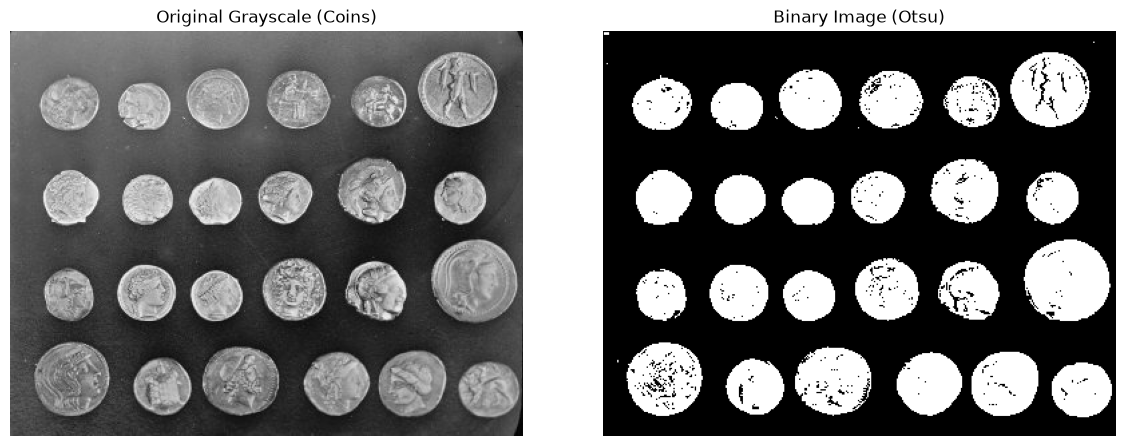

In [2]:
try:
    from skimage import data
    gray = data.coins()                      # built-in image in scikit-image
except ImportError:
    gray = cv2.imread("coins.png", cv2.IMREAD_GRAYSCALE)   # fallback: image file next to the notebook

# correct the uneven lighting: subtract the smooth background
g = gray.astype(np.float32)
background = cv2.GaussianBlur(g, (0, 0), 60)
corrected = cv2.normalize(g - background, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# convert to binary with Otsu thresholding
_, binary = cv2.threshold(corrected, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Shape:", binary.shape, "| Unique values:", np.unique(binary))

plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1); plt.imshow(gray, cmap="gray");   plt.title("Original Grayscale (Coins)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(binary, cmap="gray"); plt.title("Binary Image (Otsu)");        plt.axis("off")
plt.tight_layout()
plt.show()

In [3]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

erosion  = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

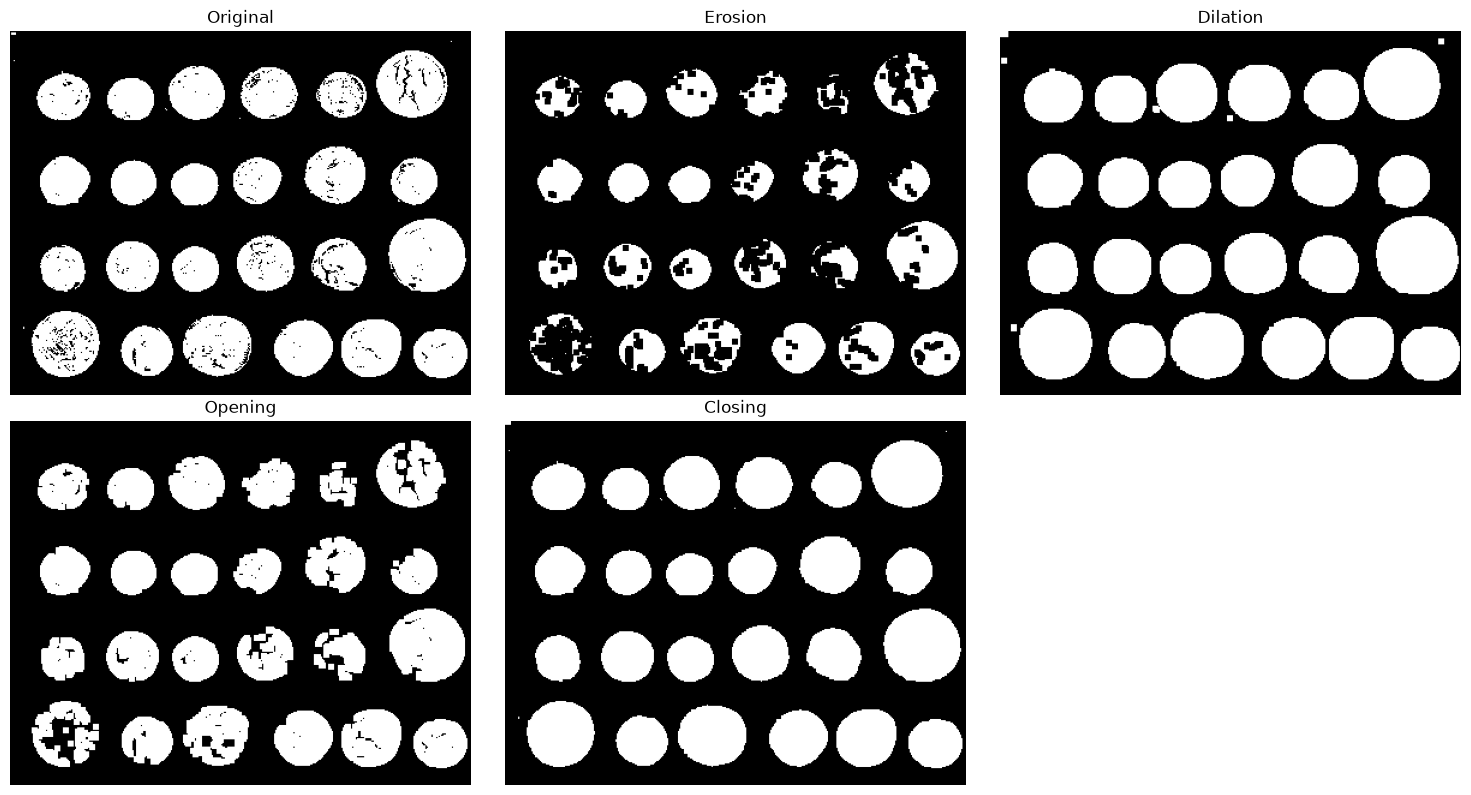

Original :  37276 white pixels
Erosion  :  20809 white pixels
Dilation :  48060 white pixels
Opening  :  34127 white pixels
Closing  :  38844 white pixels


In [4]:
images = [binary, erosion, dilation, opening, closing]
titles = ["Original", "Erosion", "Dilation", "Opening", "Closing"]

plt.figure(figsize=(15, 8))
for i, (im, t) in enumerate(zip(images, titles)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(im, cmap="gray")
    plt.title(t)
    plt.axis("off")
plt.tight_layout()
plt.show()

# count white pixels to compare the operations numerically
for t, im in zip(titles, images):
    print(f"{t:<9}: {np.count_nonzero(im):>6} white pixels")

In [5]:
shapes = {
    "Square":  cv2.MORPH_RECT,
    "Cross":   cv2.MORPH_CROSS,
    "Ellipse": cv2.MORPH_ELLIPSE,
}
sizes = [3, 5, 7]

# print the 7x7 kernels to see the shape of each one
for name, s in shapes.items():
    print(f"{name} 7x7:")
    print(cv2.getStructuringElement(s, (7, 7)), "\n")

Square 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]] 

Cross 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]] 

Ellipse 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]] 



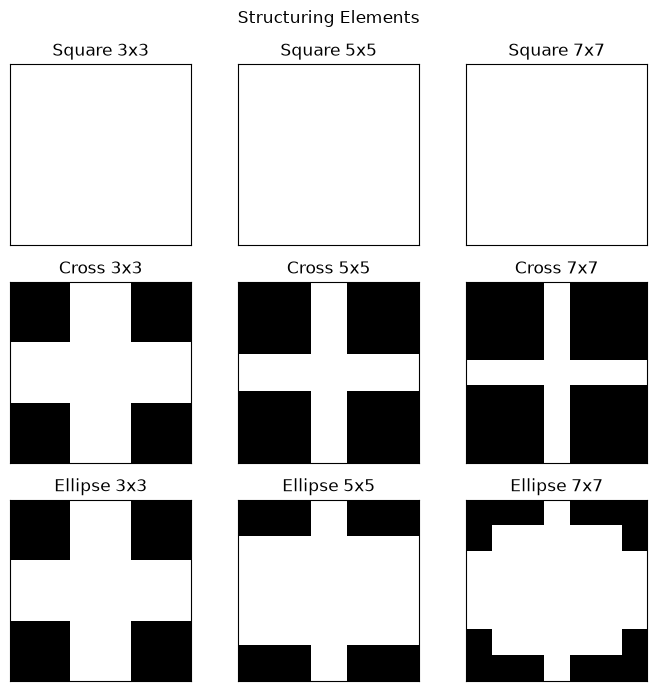

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for r, (name, s) in enumerate(shapes.items()):
    for c, k in enumerate(sizes):
        se = cv2.getStructuringElement(s, (k, k))
        axes[r, c].imshow(se, cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"{name} {k}x{k}")
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
plt.suptitle("Structuring Elements")
plt.tight_layout()
plt.show()

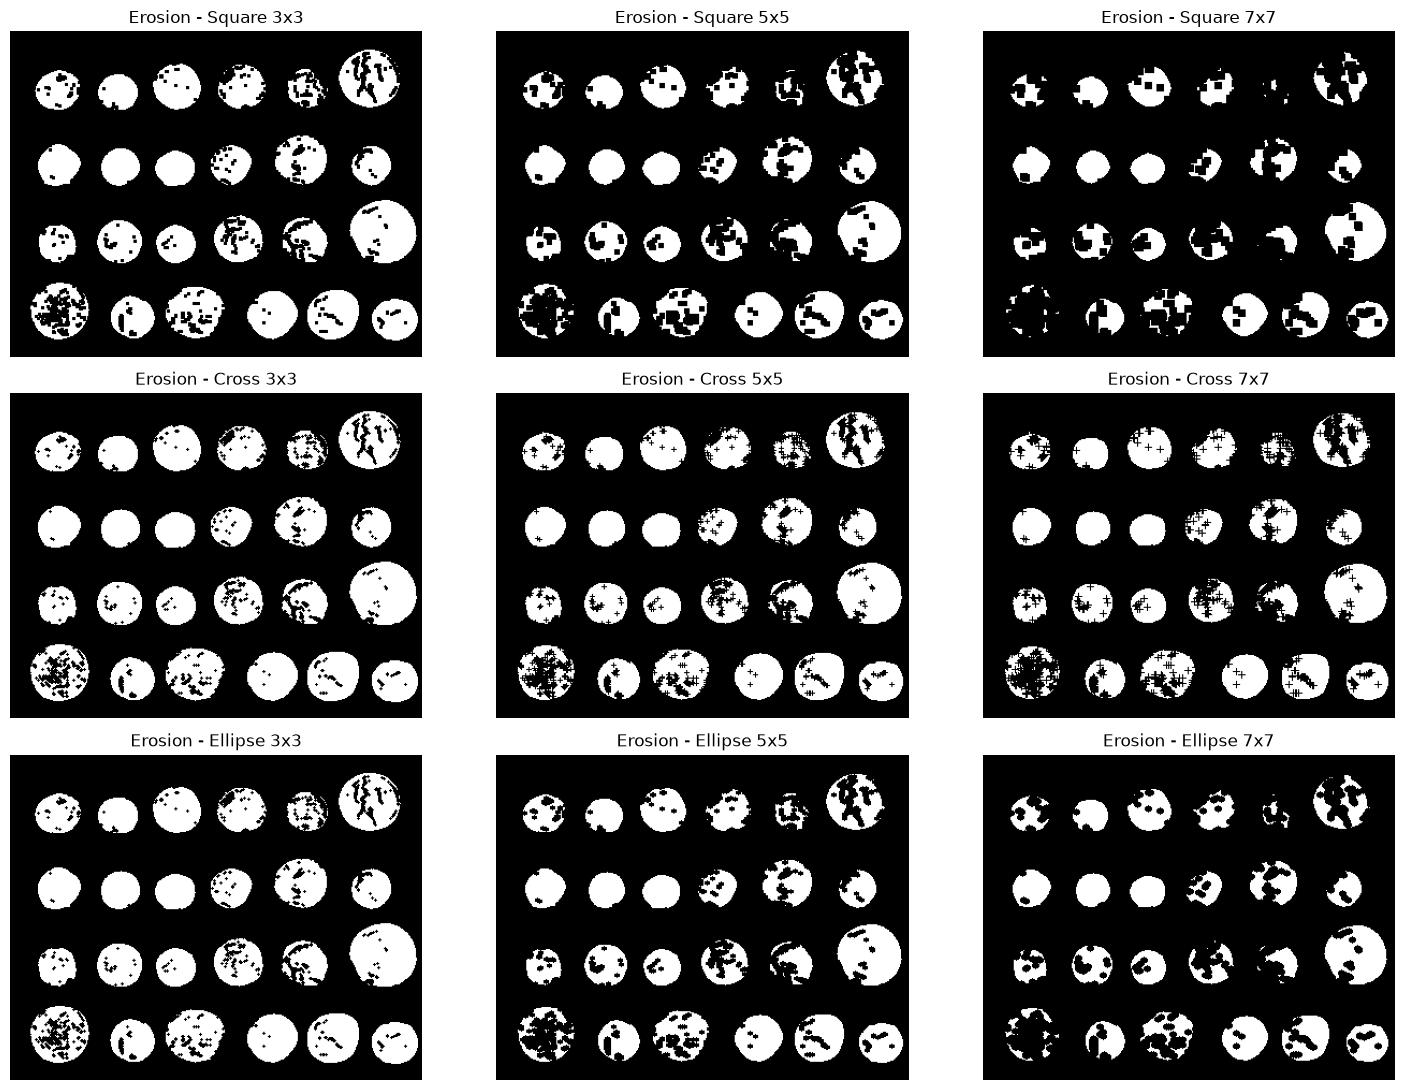

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (name, s) in enumerate(shapes.items()):
    for c, k in enumerate(sizes):
        se = cv2.getStructuringElement(s, (k, k))
        out = cv2.erode(binary, se)
        axes[r, c].imshow(out, cmap="gray")
        axes[r, c].set_title(f"Erosion - {name} {k}x{k}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

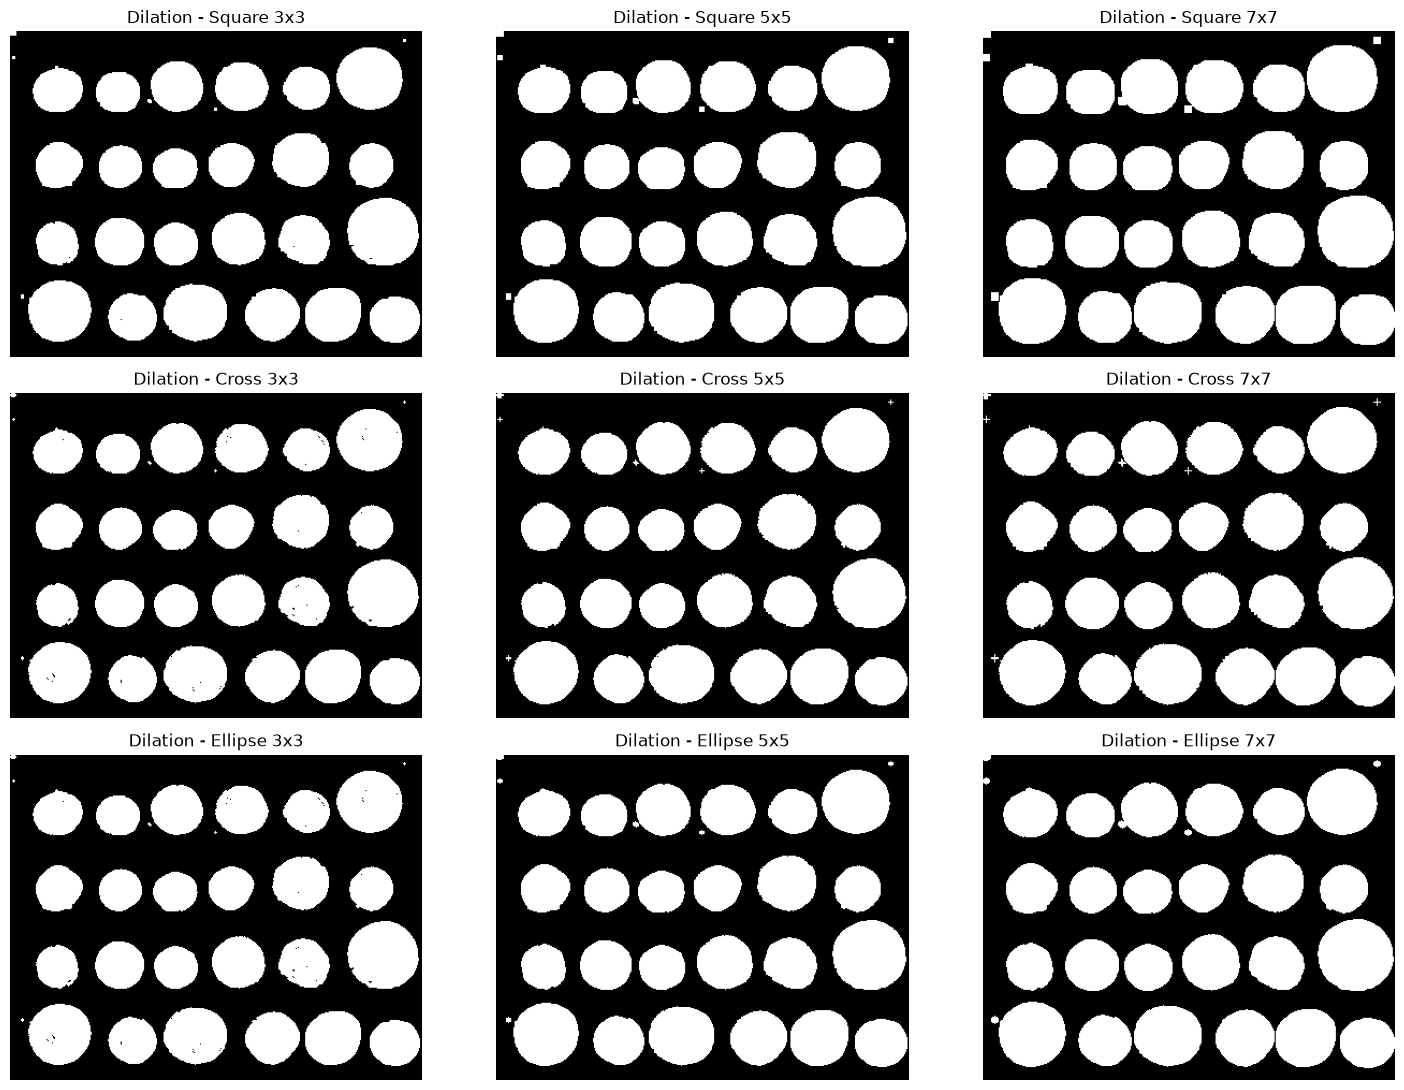

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (name, s) in enumerate(shapes.items()):
    for c, k in enumerate(sizes):
        se = cv2.getStructuringElement(s, (k, k))
        out = cv2.dilate(binary, se)
        axes[r, c].imshow(out, cmap="gray")
        axes[r, c].set_title(f"Dilation - {name} {k}x{k}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

In [9]:
base = np.count_nonzero(binary)
print(f"Original white pixels: {base}\n")
print(f"{'Shape':<8} {'Size':<6} {'Erosion':>9} {'Change %':>9} {'Dilation':>9} {'Change %':>9}")
print("-" * 56)
for name, s in shapes.items():
    for k in sizes:
        se = cv2.getStructuringElement(s, (k, k))
        e = np.count_nonzero(cv2.erode(binary, se))
        d = np.count_nonzero(cv2.dilate(binary, se))
        print(f"{name:<8} {k}x{k:<4} {e:>9} {100*(e-base)/base:>8.1f}% {d:>9} {100*(d-base)/base:>8.1f}%")

Original white pixels: 37276

Shape    Size     Erosion  Change %  Dilation  Change %
--------------------------------------------------------
Square   3x3        28532    -23.5%     43325     16.2%
Square   5x5        20809    -44.2%     48060     28.9%
Square   7x7        14614    -60.8%     53007     42.2%
Cross    3x3        31297    -16.0%     41948     12.5%
Cross    5x5        26467    -29.0%     45209     21.3%
Cross    7x7        22393    -39.9%     48512     30.1%
Ellipse  3x3        31297    -16.0%     41948     12.5%
Ellipse  5x5        23757    -36.3%     46253     24.1%
Ellipse  7x7        18470    -50.5%     49796     33.6%
